Breast Cancer Data Analysis - Summary

## 1. Project Goal
This project analyzes a breast cancer dataset to explore clinical and molecular features and build predictive models to determine patient status (Alive or Dead).

## 2. Key Steps
- **Data Exploration:** Explored distributions of Tumor Stage, Surgery Type, Patient Status, Hormone Receptor status, and Histology using SQL queries.
- **Bivariate Analysis:** Investigated relationships between clinical factors such as Histology vs. PR Status and Surgery Type vs. Patient Status.
- **Predictive Modeling:** Built Logistic Regression and Random Forest models using Age and Protein levels to predict patient outcomes.
- **Visualization & Insights:** Used countplots, boxplots, and a correlation heatmap to better understand data patterns, and analyzed feature importance to determine key factors affecting patient status.

In [1]:
import pandas as pd
from pandasql import sqldf

In [2]:
df = pd.read_csv('/kaggle/input/datasets/amandam1/breastcancerdataset/BRCA.csv')

In [3]:
query = "SELECT * FROM df LIMIT 5"
result = sqldf(query)
print(result)

     Patient_ID   Age  Gender  Protein1  Protein2  Protein3  Protein4  \
0  TCGA-D8-A1XD  36.0  FEMALE  0.080353   0.42638   0.54715  0.273680   
1  TCGA-EW-A1OX  43.0  FEMALE -0.420320   0.57807   0.61447 -0.031505   
2  TCGA-A8-A079  69.0  FEMALE  0.213980   1.31140  -0.32747 -0.234260   
3  TCGA-D8-A1XR  56.0  FEMALE  0.345090  -0.21147  -0.19304  0.124270   
4  TCGA-BH-A0BF  56.0  FEMALE  0.221550   1.90680   0.52045 -0.311990   

  Tumour_Stage                      Histology ER status PR status HER2 status  \
0          III  Infiltrating Ductal Carcinoma  Positive  Positive    Negative   
1           II             Mucinous Carcinoma  Positive  Positive    Negative   
2          III  Infiltrating Ductal Carcinoma  Positive  Positive    Negative   
3           II  Infiltrating Ductal Carcinoma  Positive  Positive    Negative   
4           II  Infiltrating Ductal Carcinoma  Positive  Positive    Negative   

                  Surgery_type Date_of_Surgery Date_of_Last_Visit  \
0  Mo

In [4]:
query = "SELECT Tumour_Stage, COUNT(*) as Count FROM df GROUP BY Tumour_Stage"
result = sqldf(query)
print(result)

  Tumour_Stage  Count
0         None      7
1            I     64
2           II    189
3          III     81


In [5]:
query = "SELECT Surgery_type, COUNT(*) as Count FROM df GROUP BY Surgery_type"
result = sqldf(query)
print(result)

                  Surgery_type  Count
0                         None      7
1                   Lumpectomy     66
2  Modified Radical Mastectomy     96
3                        Other    105
4            Simple Mastectomy     67


In [6]:
query = "SELECT Patient_Status, COUNT(*) as Count FROM df GROUP BY Patient_Status"
result = sqldf(query)
print(result)

  Patient_Status  Count
0           None     20
1          Alive    255
2           Dead     66


In [7]:
query = 'SELECT "ER status", COUNT(*) as Count FROM df GROUP BY "ER status"'
result = sqldf(query)
print(result)

  ER status  Count
0      None      7
1  Positive    334


In [8]:
query = 'SELECT "PR status", COUNT(*) as Count FROM df GROUP BY "PR status"'
result = sqldf(query)
print(result)

  PR status  Count
0      None      7
1  Positive    334


In [9]:
query = 'SELECT "HER2 status", COUNT(*) as Count FROM df GROUP BY "HER2 status"'
result = sqldf(query)
print(result)

  HER2 status  Count
0        None      7
1    Negative    305
2    Positive     29


In [10]:
query = "SELECT Histology, COUNT(*) as Count FROM df GROUP BY Histology"
result = sqldf(query)
print(result)

                        Histology  Count
0                            None      7
1   Infiltrating Ductal Carcinoma    233
2  Infiltrating Lobular Carcinoma     89
3              Mucinous Carcinoma     12


In [11]:
query = """
SELECT 
    Histology, 
    SUM(CASE WHEN "PR status" = 'Positive' THEN 1 ELSE 0 END) AS Positive, 
    SUM(CASE WHEN "PR status" = 'Negative' THEN 1 ELSE 0 END) AS Negative, 
    COUNT(*) AS Total 
FROM df 
GROUP BY Histology
"""
result = sqldf(query)
print(result)

                        Histology  Positive  Negative  Total
0                            None         0         0      7
1   Infiltrating Ductal Carcinoma       233         0    233
2  Infiltrating Lobular Carcinoma        89         0     89
3              Mucinous Carcinoma        12         0     12


In [12]:
query = """
SELECT 
    Tumour_Stage, 
    SUM(CASE WHEN Patient_Status = 'Alive' THEN 1 ELSE 0 END) AS Alive, 
    SUM(CASE WHEN Patient_Status = 'Dead' THEN 1 ELSE 0 END) AS Dead, 
    COUNT(*) AS Total 
FROM df 
GROUP BY Tumour_Stage
"""
result = sqldf(query)
print(result)

  Tumour_Stage  Alive  Dead  Total
0         None      0     0      7
1            I     51    10     64
2           II    144    38    189
3          III     60    18     81


In [13]:
query = """
SELECT 
    Surgery_type, 
    SUM(CASE WHEN Patient_Status = 'Alive' THEN 1 ELSE 0 END) AS Alive, 
    SUM(CASE WHEN Patient_Status = 'Dead' THEN 1 ELSE 0 END) AS Dead, 
    COUNT(*) AS Total 
FROM df 
GROUP BY Surgery_type
"""
result = sqldf(query)
print(result)

                  Surgery_type  Alive  Dead  Total
0                         None      0     0      7
1                   Lumpectomy     57     9     66
2  Modified Radical Mastectomy     72    20     96
3                        Other     73    25    105
4            Simple Mastectomy     53    12     67


In [14]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

In [15]:
df = df.dropna(subset=['Age', 'Protein1', 'Protein2', 'Protein3', 'Protein4', 'Patient_Status'])

Accuracy: 0.8153846153846154


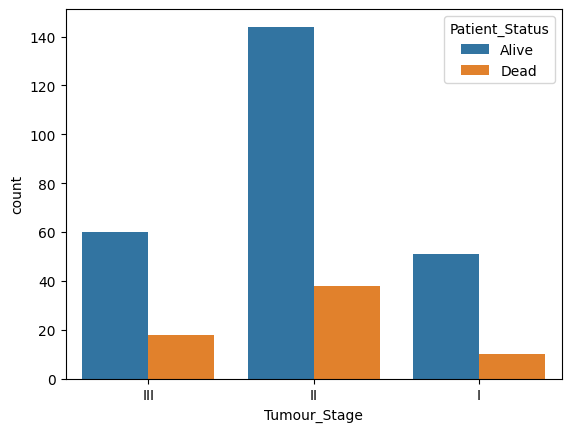

In [16]:
X = df[['Age', 'Protein1', 'Protein2', 'Protein3', 'Protein4']]
y = df['Patient_Status']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, predictions))

sns.countplot(x='Tumour_Stage', hue='Patient_Status', data=df)
plt.show()

In [17]:
from sklearn.ensemble import RandomForestClassifier

X = df[['Age', 'Protein1', 'Protein2', 'Protein3', 'Protein4']]
y = df['Patient_Status']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)
print("Random Forest Accuracy:", accuracy_score(y_test, rf_predictions))

Random Forest Accuracy: 0.7846153846153846


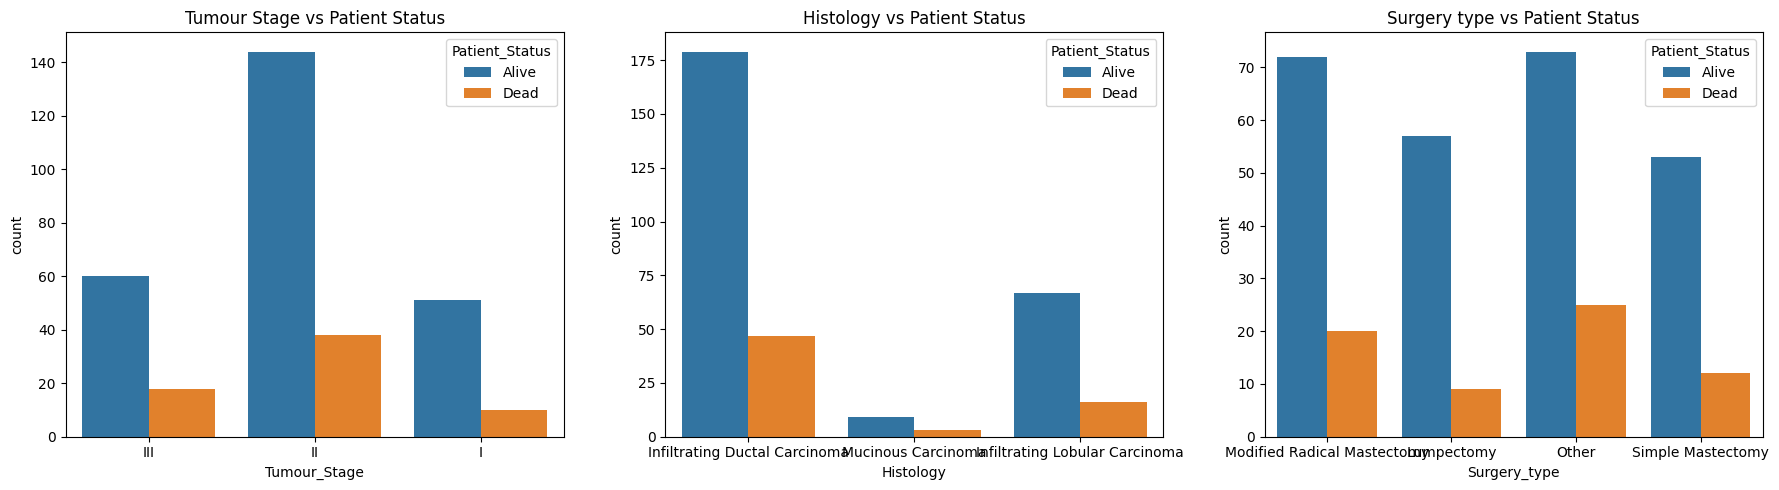

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.countplot(ax=axes[0], x='Tumour_Stage', hue='Patient_Status', data=df)
axes[0].set_title('Tumour Stage vs Patient Status')

sns.countplot(ax=axes[1], x='Histology', hue='Patient_Status', data=df)
axes[1].set_title('Histology vs Patient Status')

sns.countplot(ax=axes[2], x='Surgery_type', hue='Patient_Status', data=df)
axes[2].set_title('Surgery type vs Patient Status')

plt.tight_layout()
plt.show()

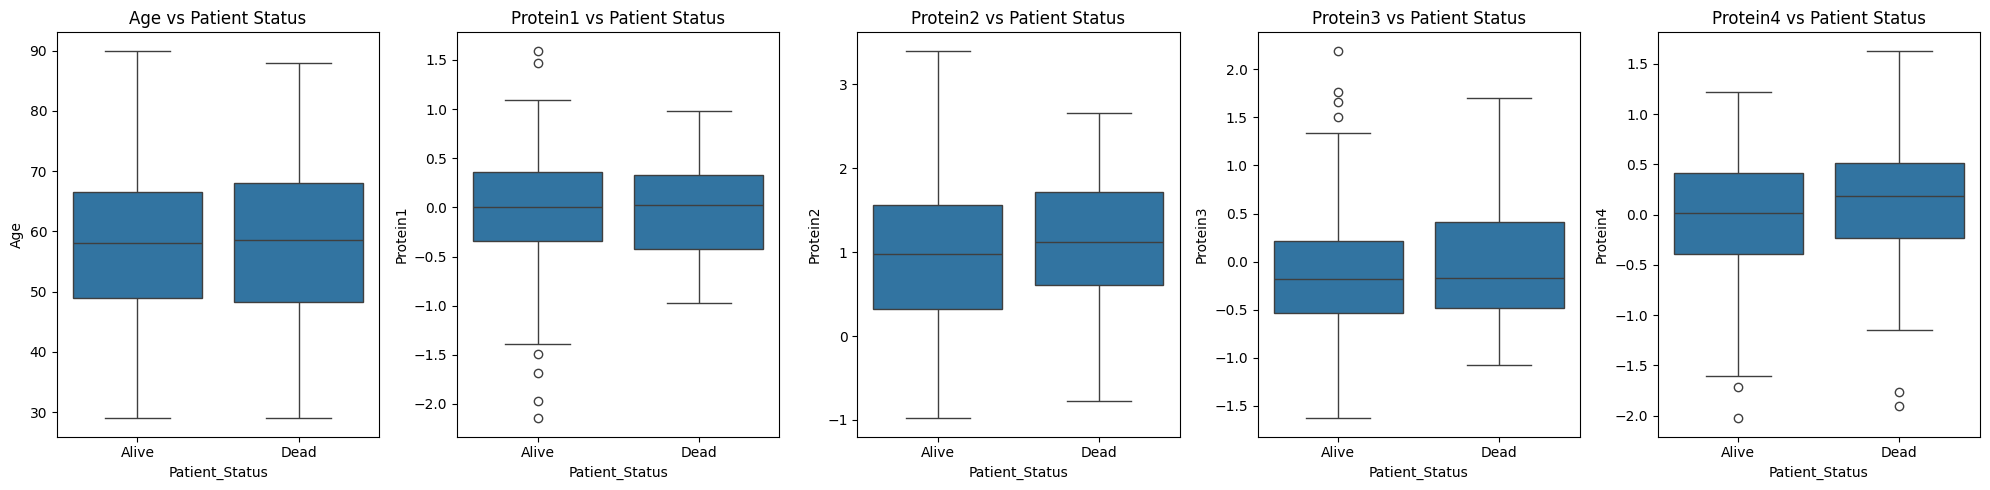

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

features = ['Age', 'Protein1', 'Protein2', 'Protein3', 'Protein4']

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for i, feature in enumerate(features):
    sns.boxplot(ax=axes[i], x='Patient_Status', y=feature, data=df)
    axes[i].set_title(feature + ' vs Patient Status')

plt.tight_layout()
plt.show()

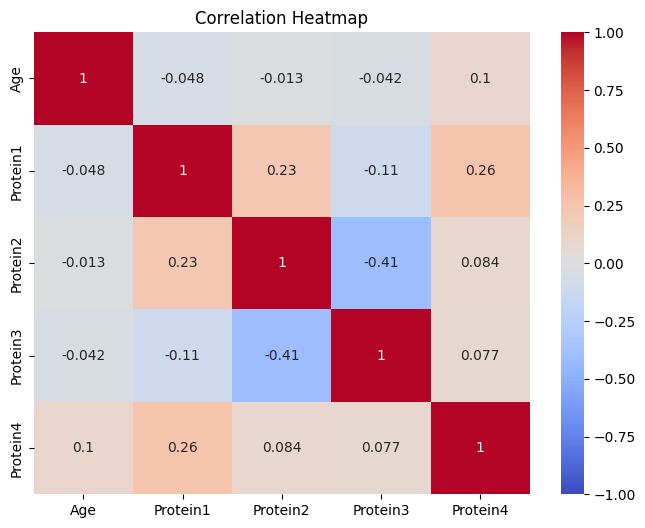

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
sns.heatmap(df[['Age', 'Protein1', 'Protein2', 'Protein3', 'Protein4']].corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap')
plt.show()

In [21]:
import pandas as pd
import numpy as np

importance = pd.DataFrame(
    {"Feature": X.columns, "Importance": rf_model.feature_importances_}
).sort_values(by="Importance", ascending=False)
print(importance)

    Feature  Importance
3  Protein3    0.237529
4  Protein4    0.224969
2  Protein2    0.201400
1  Protein1    0.189689
0       Age    0.146413
